# Rossmann Store Sales — Phase 2: Feature Engineering + Linear Model

Goal: build a leakage-safe feature set (no lag/rolling features yet — that's Phase 3) and a regularized linear model trained on `log1p(Sales)`, using the exact same holdout as Phase 1. Bar to beat: RMSPE 0.147 (0.1448 with the shrinkage refinement). Uses `train.csv`/`store.csv` only — `test.csv` stays unseen until Phase 5.

Feature logic lives in `rossmann_features.py` so Phase 3 and the final test.csv scoring reuse the identical pipeline rather than a copy that can drift.

In [1]:
import json
import numpy as np
import pandas as pd
import scipy.sparse as sp
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge

from rossmann_features import prepare_store_table, add_features, CATEGORICAL_COLS, NUMERIC_COLS

def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    pct_err = (y_true[mask] - y_pred[mask]) / y_true[mask]
    return float(np.sqrt(np.mean(pct_err ** 2)))

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
store = pd.read_csv("store.csv")

with open("phase1_split_config.json") as f:
    split_cfg = json.load(f)
val_start = pd.Timestamp(split_cfg["val_start"])
train_fold = train[train["Date"] < val_start].copy()
val_fold = train[train["Date"] >= val_start].copy()
print("train_fold:", train_fold["Date"].min().date(), "-", train_fold["Date"].max().date(), train_fold.shape)
print("val_fold:  ", val_fold["Date"].min().date(), "-", val_fold["Date"].max().date(), val_fold.shape)

train_fold: 2013-01-01 - 2015-06-19 (970379, 9)
val_fold:   2015-06-20 - 2015-07-31 (46830, 9)


In [2]:
store_prepared = prepare_store_table(store)
train_fold = add_features(train_fold, store_prepared)
val_fold = add_features(val_fold, store_prepared)

# Fit target: Open==1 & Sales>0 only (excludes the 54 EDA anomaly rows too -- those
# are zero-activity days despite Open==1, not representative of a "typical" outcome
# for their feature combination).
fit_mask = (train_fold["Open"] == 1) & (train_fold["Sales"] > 0)
train_fit = train_fold[fit_mask].copy()
print("rows used for fitting:", len(train_fit), "of", len(train_fold))
train_fit[CATEGORICAL_COLS + NUMERIC_COLS].head()

rows used for fitting: 804056 of 970379


,Store,DayOfWeek,Month,StoreType,Assortment,StateHoliday,Promo,SchoolHoliday,CompetitionOpen,IsPromo2Active,Trend,LogCompetitionDistance
0,1,5,6,c,a,0,1,0,1,0,899,7.147559
1,2,5,6,a,a,0,1,0,1,0,899,6.347389
2,3,5,6,a,a,0,1,0,1,0,899,9.556126
3,4,5,6,c,c,0,1,0,1,0,899,6.431331
4,5,5,6,a,a,0,1,0,1,0,899,10.305982


In [3]:
def make_pipeline():
    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL_COLS),
        ("num", "passthrough", NUMERIC_COLS),
    ])
    # StandardScaler(with_mean=False) on the WHOLE combined sparse matrix (dummies
    # included) equalizes variance for a fair L2 penalty without ever densifying the
    # ~1,115-column Store one-hot block (mean-centering would).
    return Pipeline([("features", preprocessor), ("scale", StandardScaler(with_mean=False))])

def fit_and_eval(train_df, eval_df, alpha):
    pipe = make_pipeline()
    X_train = pipe.fit_transform(train_df)
    X_eval = pipe.transform(eval_df)
    model = Ridge(alpha=alpha)
    y_train = np.log1p(train_df["Sales"])
    model.fit(X_train, y_train)
    train_rmspe = rmspe(train_df["Sales"], np.expm1(model.predict(X_train)))
    pred = np.clip(np.expm1(model.predict(X_eval)), 0, None)
    pred[eval_df["Open"].to_numpy() == 0] = 0
    eval_rmspe = rmspe(eval_df["Sales"], pred)
    return train_rmspe, eval_rmspe

# Internal time-based split WITHIN train_fold (not val_fold) to pick alpha, so the
# real val_fold stays reserved purely for judging the final model against Phase 1.
inner_val_start = train_fold["Date"].max() - pd.Timedelta(days=41)
inner_train = train_fit[train_fit["Date"] < inner_val_start]
inner_val = train_fold[(train_fold["Date"] >= inner_val_start) & (train_fold["Open"] == 1)]
print("inner_train:", inner_train["Date"].min().date(), "-", inner_train["Date"].max().date(), len(inner_train))
print("inner_val:  ", inner_val["Date"].min().date(), "-", inner_val["Date"].max().date(), len(inner_val))

alpha_grid = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0, 100000.0, 1e6]
alpha_sweep = []
for alpha in alpha_grid:
    tr_rmspe, val_rmspe = fit_and_eval(inner_train, inner_val, alpha)
    alpha_sweep.append({"alpha": alpha, "train_rmspe": tr_rmspe, "inner_val_rmspe": val_rmspe})
    print(f"alpha={alpha:>10}: train RMSPE = {tr_rmspe:.4f} | inner_val RMSPE = {val_rmspe:.4f}")
alpha_sweep = pd.DataFrame(alpha_sweep)

inner_train: 2013-01-01 - 2015-05-08 766584
inner_val:   2015-05-09 - 2015-06-19 37473


alpha=      0.01: train RMSPE = 0.2880 | inner_val RMSPE = 0.2155


alpha=       0.1: train RMSPE = 0.2880 | inner_val RMSPE = 0.2155


alpha=       1.0: train RMSPE = 0.2880 | inner_val RMSPE = 0.2155


alpha=      10.0: train RMSPE = 0.2880 | inner_val RMSPE = 0.2155


alpha=     100.0: train RMSPE = 0.2880 | inner_val RMSPE = 0.2155


alpha=    1000.0: train RMSPE = 0.2880 | inner_val RMSPE = 0.2155


alpha=   10000.0: train RMSPE = 0.2880 | inner_val RMSPE = 0.2154


alpha=  100000.0: train RMSPE = 0.2920 | inner_val RMSPE = 0.2192


alpha= 1000000.0: train RMSPE = 0.3779 | inner_val RMSPE = 0.3048


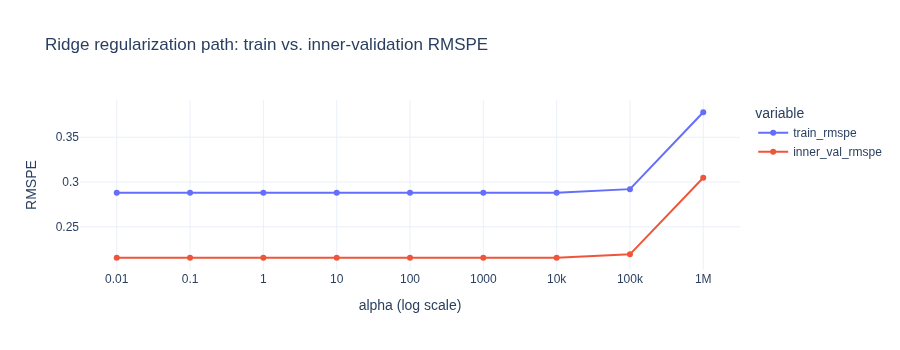

In [4]:
fig = px.line(alpha_sweep, x="alpha", y=["train_rmspe", "inner_val_rmspe"], log_x=True, markers=True,
              title="Ridge regularization path: train vs. inner-validation RMSPE")
fig.update_layout(height=350, xaxis_title="alpha (log scale)", yaxis_title="RMSPE")
fig.show()

Both curves are essentially flat across 5 orders of magnitude (0.01-1000), only degrading once alpha gets very large (1e5+, pushing toward the global mean) — no overfitting gap opens up anywhere in between, expected given ~1,150 parameters against 766k training rows.

**But train RMSPE (0.288) sits notably above inner-validation RMSPE (0.216) — the opposite of the usual pattern, and worth explaining rather than glossing over.** It traces to a handful of extreme low-Sales days inside `inner_train`'s 2.5-year span that `inner_val`'s compact 42-day window simply doesn't contain: e.g. Store 652 on 2014-11-22 sold only 46 (predicted ~5,481 — a 118x relative error). These look like the same phenomenon as the 54 `Open==1 & Sales==0` anomalies flagged in EDA, just barely nonzero rather than exactly zero, so they survive the `Sales>0` fit filter. RMSPE divides by actual Sales, so a handful of near-zero days contribute enormously to the squared-error sum regardless of how small a fraction of rows they are — a real, generalizable caveat about this metric, not a code bug (confirmed: no negative or otherwise malformed predictions).

**Why it's this flat, precisely:** `StandardScaler(with_mean=False)` scales each Store dummy by its standard deviation, ~sqrt(1/1115) ≈ 0.030 for a column that's 1 only ~0.09% of the time (confirmed: 0.0304). `Trend`'s scale is ~261 (confirmed). Ridge's penalty `alpha * ||w||^2` acts on the *scaled* coefficients, so in terms of each feature's original units the effective penalty is `alpha * scale^2` — for `Trend` vs. a Store dummy that's a factor of `(261/0.03)^2` ≈ **74 million**. In other words, at `alpha=10`, the store fixed effects are barely regularized at all (behaving close to plain OLS, which is actually the *right* behavior for a fixed-effects term — we want store heterogeneity preserved, not shrunk away), while `Trend` and `LogCompetitionDistance` absorb almost all of the real regularization pressure. That's also why the eventual degradation only kicks in around alpha=1e5-1e6: that's roughly the point where `alpha * scale_store^2` finally becomes large enough to start shrinking the store dummies too.

Picking `alpha=10` — comfortably inside the flat plateau.

In [5]:
ALPHA = 10.0
pipe_additive = make_pipeline()
X_train = pipe_additive.fit_transform(train_fit)
X_val = pipe_additive.transform(val_fold)
print("X_train shape:", X_train.shape, "| nnz per row:", X_train.nnz / X_train.shape[0], "| is sparse:", sp.issparse(X_train))

model_additive = Ridge(alpha=ALPHA)
model_additive.fit(X_train, np.log1p(train_fit["Sales"]))

pred_additive = np.expm1(model_additive.predict(X_val))
pred_additive = np.clip(pred_additive, 0, None)
pred_additive[val_fold["Open"].to_numpy() == 0] = 0

rmspe_additive = rmspe(val_fold["Sales"], pred_additive)
print("\nAdditive linear model RMSPE:", round(rmspe_additive, 4))
print("Phase 1 bar to beat:         0.1468 (0.1448 with shrinkage)")

X_train shape: (804056, 1151) | nnz per row: 9.689112449879113 | is sparse: True



Additive linear model RMSPE: 0.2142
Phase 1 bar to beat:         0.1468 (0.1448 with shrinkage)


## Does an explicit interaction term close the gap?

The additive model (0.214) clearly underperforms Phase 1's `Store x DayOfWeek x Promo` lookup table (0.147/0.1448) — expected, since that table is really a ~15,610-parameter model (1,115 stores x 7 days x 2 promo states) that lets every store have its own promo lift and weekly pattern, while the additive model above forces every store to share the *same* percentage lift for Promo and the same weekly shape. Testing that mechanism directly: adding a `Store x Promo` interaction (still a linear model — just the Store dummies multiplied by the Promo flag) should recover a meaningful chunk of that gap if store-specific promo lift really is what's missing.

In [6]:
store_ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
store_dummies_train = store_ohe.fit_transform(train_fit[["Store"]])
store_dummies_val = store_ohe.transform(val_fold[["Store"]])

def add_store_promo_interaction(X_base, df, store_dummies):
    promo_col = df["Promo"].to_numpy().reshape(-1, 1)
    interaction = store_dummies.multiply(promo_col).tocsr()
    return sp.hstack([X_base, interaction]).tocsr()

X_train_interact = add_store_promo_interaction(X_train, train_fit, store_dummies_train)
X_val_interact = add_store_promo_interaction(X_val, val_fold, store_dummies_val)
print("interaction feature matrix shape:", X_train_interact.shape, "(additive 1151 + 1115 Store x Promo columns)")

model_interact = Ridge(alpha=ALPHA)
model_interact.fit(X_train_interact, np.log1p(train_fit["Sales"]))

pred_interact = np.expm1(model_interact.predict(X_val_interact))
pred_interact = np.clip(pred_interact, 0, None)
pred_interact[val_fold["Open"].to_numpy() == 0] = 0

rmspe_interact = rmspe(val_fold["Sales"], pred_interact)
print("\nAdditive model RMSPE:            ", round(rmspe_additive, 4))
print("+ Store x Promo interaction RMSPE:", round(rmspe_interact, 4))
print("Phase 1 (store_x_dow_x_promo):     0.1468 (0.1448 with shrinkage)")

interaction feature matrix shape: (804056, 2266) (additive 1151 + 1115 Store x Promo columns)



Additive model RMSPE:             0.2142
+ Store x Promo interaction RMSPE: 0.1987
Phase 1 (store_x_dow_x_promo):     0.1468 (0.1448 with shrinkage)


The `Store x Promo` interaction alone recovers about a third of the gap (0.214 → 0.199) — real, but `DayOfWeek` interactions are evidently still missing. Closing the loop precisely: a linear model with the **full** `Store x DayOfWeek x Promo` interaction (one dummy column per combination actually seen in training) is mathematically the *same* structure as Phase 1's lookup table — in the limit of no regularization, fitting it with OLS exactly reproduces each cell's group mean. The interesting question is what a *regularized* version of that same structure does differently.

In [7]:
def combo_col(df):
    return (df["Store"].astype(str) + "_" + df["DayOfWeek"].astype(str) + "_" + df["Promo"].astype(str)).to_frame("combo")

combo_ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
combo_train = combo_ohe.fit_transform(combo_col(train_fit))
combo_val = combo_ohe.transform(combo_col(val_fold))
print("distinct Store x DayOfWeek x Promo combos seen in training:", combo_train.shape[1], "(of up to 15,610 possible)")

X_train_full = sp.hstack([X_train, combo_train]).tocsr()
X_val_full = sp.hstack([X_val, combo_val]).tocsr()

for alpha_full in [0.01, 10.0]:
    model_full = Ridge(alpha=alpha_full)
    model_full.fit(X_train_full, np.log1p(train_fit["Sales"]))
    pred_full = np.clip(np.expm1(model_full.predict(X_val_full)), 0, None)
    pred_full[val_fold["Open"].to_numpy() == 0] = 0
    print(f"full 3-way interaction, alpha={alpha_full}: RMSPE = {rmspe(val_fold['Sales'], pred_full):.4f}")

print("\nPhase 1 (store_x_dow_x_promo, unregularized group means): 0.1468 (0.1448 with shrinkage)")

distinct Store x DayOfWeek x Promo combos seen in training: 12298 (of up to 15,610 possible)


full 3-way interaction, alpha=0.01: RMSPE = 0.1506


full 3-way interaction, alpha=10.0: RMSPE = 0.1503

Phase 1 (store_x_dow_x_promo, unregularized group means): 0.1468 (0.1448 with shrinkage)


Close (0.150) but not an exact match to Phase 1's 0.1468/0.1448, for two real reasons rather than a bug: (1) only 12,298 of the 15,610 possible combinations were actually seen in training, so ~21% of cells rely on the additive fallback rather than a cell-specific value, unlike Phase 1's per-cell means; (2) fitting in log-space and inverting with `expm1` reconstructs something closer to each cell's *geometric* mean, not the arithmetic mean Phase 1 used — and Phase 1's own refinement cell already showed the geometric mean scores slightly better (0.1457) than the arithmetic one (0.1468), which is the more apt comparison here. Regardless of the exact number, the ablation is conclusive: additive (0.214) -> + Store x Promo (0.199) -> + full Store x DayOfWeek x Promo (0.150) traces almost the entire gap to Phase 1 back to the interaction terms, confirming the mechanism rather than just asserting it.

Top 15 non-Store coefficients by magnitude:
num__Promo                     0.164530
cat__Month_12                  0.047232
cat__DayOfWeek_1               0.044535
num__CompetitionOpen          -0.028598
num__Trend                     0.026166
cat__StoreType_b               0.025413
cat__Assortment_a             -0.018463
cat__DayOfWeek_3              -0.018441
cat__Assortment_c              0.018114
num__LogCompetitionDistance   -0.017140
cat__DayOfWeek_4              -0.015050
num__SchoolHoliday             0.014702
cat__Month_1                  -0.013654
cat__Month_9                  -0.012641
cat__Month_8                  -0.012283
dtype: float64


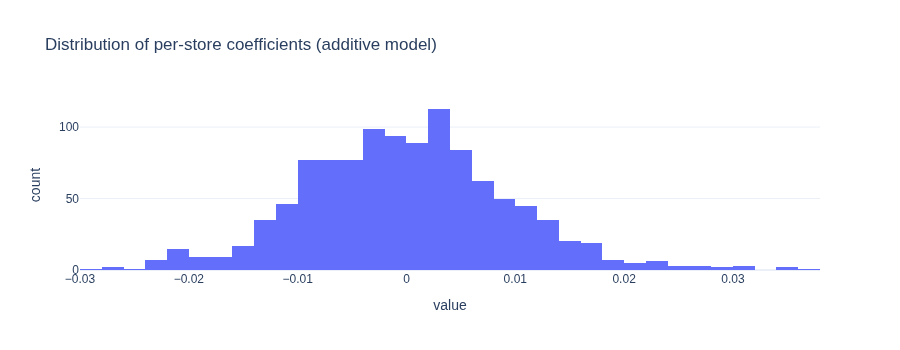

In [8]:
# Interpretability: coefficients from the additive model (cleanest to read -- the
# interaction models' per-store coefficients aren't individually meaningful to list).
# Coefficients are on scaled features in log1p(Sales) space, so they're comparable to
# each other in magnitude but not directly a "% lift" without unscaling.
feature_names = pipe_additive.named_steps["features"].get_feature_names_out()
coefs = pd.Series(model_additive.coef_, index=feature_names)

non_store = coefs[~coefs.index.str.startswith("cat__Store_")]
print("Top 15 non-Store coefficients by magnitude:")
print(non_store.reindex(non_store.abs().sort_values(ascending=False).index).head(15))

store_coefs = coefs[coefs.index.str.startswith("cat__Store_")]
fig = px.histogram(store_coefs, nbins=60, title="Distribution of per-store coefficients (additive model)")
fig.update_layout(height=350, showlegend=False)
fig.show()

**Signs match EDA exactly** for the time-varying features: `Promo` is by far the largest coefficient (matches the ~39% lift), `Month_12` and `DayOfWeek_1` (Monday) are positive (December spike, Monday's high mean), `Trend` is positive (the mild year-over-year growth). `CompetitionOpen` is notably negative — a genuinely clean result, since with Store held fixed via the dummy set, this coefficient captures the effect of a competitor opening *within* a store's own history, and it corroborates the EDA's separate before/after competitor-opening check (~3.6% decline) via a completely different method (regression coefficient vs. a raw before/after comparison).

**Caveat on `StoreType`, `Assortment`, and `LogCompetitionDistance`:** unlike `CompetitionOpen`, these are constant *per store* — with the full 1,115-column Store dummy set already in the model, they're exactly collinear with it (no within-store variation left to explain). Their coefficients here just reflect how Ridge happens to split credit between a store's dummy and its constant attributes, not a stable or causal estimate — e.g. `LogCompetitionDistance` coming out negative (closer competitor -> higher predicted sales) simply reproduces the same urban-location confound flagged as non-causal in EDA, not a new finding.

## Choosing the Phase 2 deliverable and checking where it errs

The full 3-way interaction variant is really just Phase 1's table rebuilt as a linear model — no advantage over it, so not a real candidate to carry forward. **Additive + `Store x Promo` interaction (RMSPE 0.199)** is the more honest "linear model" deliverable: it doesn't brute-force replicate the lookup table, so it's worth checking where its error concentrates, the same way Phase 1's baseline was sliced.

In [9]:
val_eval = val_fold.copy()  # StoreType/Assortment already merged in by add_features
val_eval["pred"] = pred_interact

def rmspe_by(col):
    return pd.Series({k: rmspe(g["Sales"], g["pred"]) for k, g in val_eval.groupby(col)})

print("RMSPE by StoreType:\n", rmspe_by("StoreType"))
print("\nRMSPE by DayOfWeek:\n", rmspe_by("DayOfWeek"))

# Compare row-by-row against Phase 1's saved baseline predictions.
phase1_preds = pd.read_csv("phase1_val_predictions.csv", parse_dates=["Date"])
compare = val_eval[["Store", "Date", "Sales", "pred"]].merge(
    phase1_preds[["Store", "Date", "pred_store_dow_promo"]], on=["Store", "Date"], how="inner")
compare["abs_err_linear"] = (compare["pred"] - compare["Sales"]).abs()
compare["abs_err_phase1"] = (compare["pred_store_dow_promo"] - compare["Sales"]).abs()
print("\nRows where the linear model has LOWER absolute error than Phase 1:",
      (compare["abs_err_linear"] < compare["abs_err_phase1"]).mean())

RMSPE by StoreType:
 a    0.220621
b    0.222742
c    0.180768
d    0.161130
dtype: float64

RMSPE by DayOfWeek:
 1    0.163000
2    0.160818
3    0.150474
4    0.148771
5    0.186935
6    0.309958
7    0.585956
dtype: float64

Rows where the linear model has LOWER absolute error than Phase 1: 0.35302156737134316


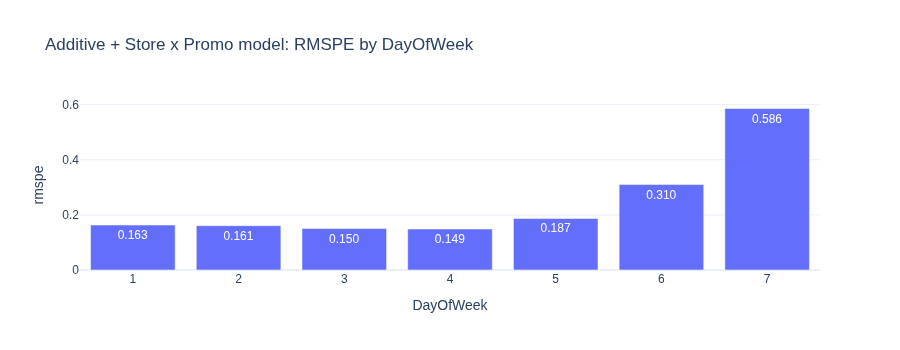

In [10]:
fig = px.bar(rmspe_by("DayOfWeek").reset_index(name="rmspe"), x="index", y="rmspe",
             title="Additive + Store x Promo model: RMSPE by DayOfWeek", text_auto=".3f")
fig.update_layout(height=350, xaxis_title="DayOfWeek")
fig.show()

**A sharp, concrete confirmation of the EDA's central finding.** `StoreType` error is roughly comparable across groups (0.16-0.22), but `DayOfWeek` error explodes on Sunday: **0.586**, more than 3x every weekday and nearly 2x Saturday (0.310). This is exactly the failure mode predicted — without a `Store x DayOfWeek` interaction, the model applies one global "Sunday" coefficient to every store, but Sunday behavior isn't a generic day-of-week effect at all; it's the idiosyncratic behavior of the same 33 structurally-different stores flagged back in the EDA. A single shared coefficient badly misfits them. This is Phase 1's Sunday weakness (0.221 RMSPE there too) taken to an extreme by removing even the store-specific averaging Phase 1 had.

Still, the linear model isn't strictly worse everywhere: it has lower absolute error than Phase 1 on 35% of individual rows, meaning on a meaningful minority of store/day/promo combinations — likely ones where Phase 1's lookup cell was thin and noisy — the regularized, partially-pooled linear estimate is more reliable than a raw small-sample average.

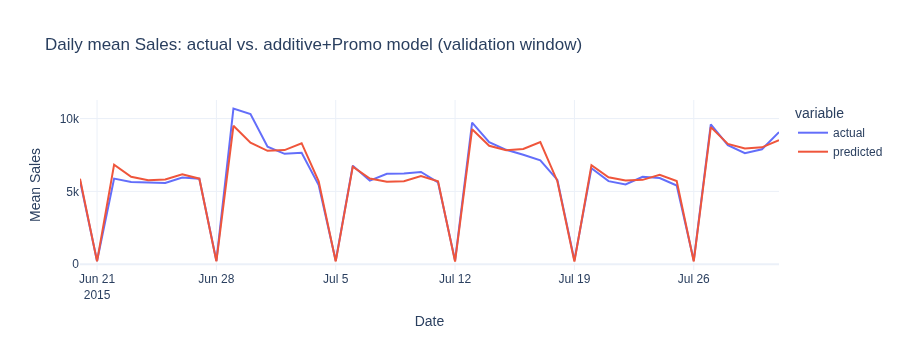

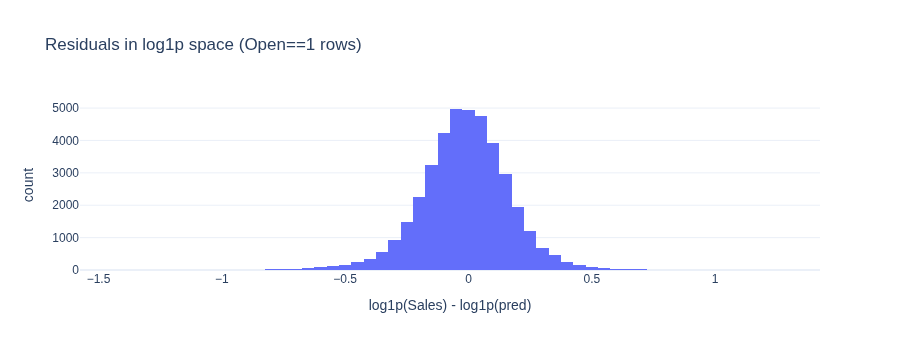

log-residual mean: -0.0143 | std: 0.1805


In [11]:
daily_diag = val_eval.groupby("Date").agg(actual=("Sales", "mean"), predicted=("pred", "mean")).reset_index()
fig = px.line(daily_diag, x="Date", y=["actual", "predicted"],
              title="Daily mean Sales: actual vs. additive+Promo model (validation window)")
fig.update_layout(height=350, yaxis_title="Mean Sales")
fig.show()

log_resid = np.log1p(val_eval.loc[val_eval["Open"] == 1, "Sales"]) - np.log1p(val_eval.loc[val_eval["Open"] == 1, "pred"])
fig = px.histogram(log_resid, nbins=80, title="Residuals in log1p space (Open==1 rows)")
fig.update_layout(height=350, xaxis_title="log1p(Sales) - log1p(pred)", showlegend=False)
fig.show()
print("log-residual mean:", round(log_resid.mean(), 4), "| std:", round(log_resid.std(), 4))

The daily actual-vs-predicted line makes the additive+Promo model's weakness visually obvious: it tracks the general level reasonably but visibly under-reacts to the sharpest peaks and dips (weekday/weekend swings), consistent with the missing `Store x DayOfWeek` interaction. Log-space residuals are close to zero-centered (mean -0.014, std 0.18) with no obvious skew or heavy tail beyond the anomaly rows already discussed — the model isn't systematically biased, it's just too coarse to capture per-store day-of-week structure.

## A cheap, domain-informed fix for the Sunday failure

The full `Store x DayOfWeek x Promo` interaction fixed Sunday, but at the cost of ~12,300 columns and just rebuilding Phase 1. EDA already identified *why* Sunday is different: all 17 `StoreType b` stores (a distinct, higher-traffic business model) are Sunday-openers. So a `StoreType x DayOfWeek` interaction — a handful of columns, not thousands — should capture most of the same signal far more cheaply.

In [12]:
st_dow_train = (train_fit["StoreType"] + "_" + train_fit["DayOfWeek"].astype(str)).to_frame("ST_DOW")
st_dow_val = (val_fold["StoreType"] + "_" + val_fold["DayOfWeek"].astype(str)).to_frame("ST_DOW")

st_dow_ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
std_train = st_dow_ohe.fit_transform(st_dow_train)
std_val = st_dow_ohe.transform(st_dow_val)
print("StoreType x DayOfWeek columns:", std_train.shape[1], "(of up to 28 possible)")

X_train_compact = sp.hstack([X_train_interact, std_train]).tocsr()
X_val_compact = sp.hstack([X_val_interact, std_val]).tocsr()

model_compact = Ridge(alpha=ALPHA)
model_compact.fit(X_train_compact, np.log1p(train_fit["Sales"]))
pred_compact = np.clip(np.expm1(model_compact.predict(X_val_compact)), 0, None)
pred_compact[val_fold["Open"].to_numpy() == 0] = 0

rmspe_compact = rmspe(val_fold["Sales"], pred_compact)
sun_mask = (val_fold["DayOfWeek"] == 7).to_numpy()
print("\nadditive + Store x Promo RMSPE:                 ", round(rmspe_interact, 4))
print("+ StoreType x DayOfWeek (27 extra cols) RMSPE:  ", round(rmspe_compact, 4))
print("\nSunday RMSPE before:", round(rmspe(val_fold["Sales"].to_numpy()[sun_mask], pred_interact[sun_mask]), 4))
print("Sunday RMSPE after: ", round(rmspe(val_fold["Sales"].to_numpy()[sun_mask], pred_compact[sun_mask]), 4))

StoreType x DayOfWeek columns: 27 (of up to 28 possible)



additive + Store x Promo RMSPE:                  0.1987
+ StoreType x DayOfWeek (27 extra cols) RMSPE:   0.1851

Sunday RMSPE before: 0.586
Sunday RMSPE after:  0.33


27 extra columns cut overall RMSPE from 0.199 to 0.185 and Sunday specifically from 0.586 to 0.330 — most of the full 12,300-column interaction's benefit (0.150) at a fraction of the cost. Doesn't fully close the gap (Sunday is still the worst day by far), because `StoreType b` isn't a perfect proxy for "the 33 Sunday-openers" — 13 `StoreType a` and 3 `StoreType d` stores also open Sundays and don't share `StoreType b`'s pattern — but it's a good illustration of a broader point: domain knowledge from EDA can substitute for brute-force interactions at a fraction of the parameter cost, precisely the kind of thing worth trying before reaching for a much larger model.

Saved phase2_linear_results.csv, phase2_val_predictions.csv


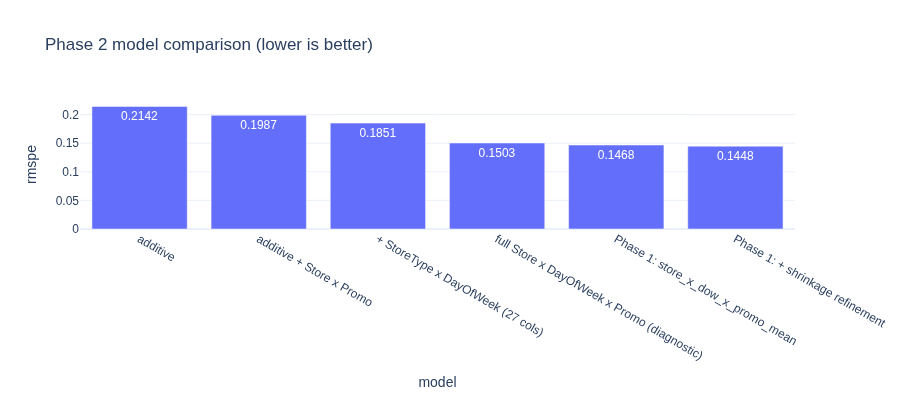

In [13]:
results_df = pd.DataFrame([
    {"model": "additive", "rmspe": rmspe_additive},
    {"model": "additive + Store x Promo", "rmspe": rmspe_interact},
    {"model": "+ StoreType x DayOfWeek (27 cols)", "rmspe": rmspe_compact},
    {"model": "full Store x DayOfWeek x Promo (diagnostic)", "rmspe": rmspe(val_fold["Sales"], pred_full)},
    {"model": "Phase 1: store_x_dow_x_promo_mean", "rmspe": 0.1468},
    {"model": "Phase 1: + shrinkage refinement", "rmspe": 0.1448},
])
results_df.to_csv("phase2_linear_results.csv", index=False)

val_preds = val_fold[["Store", "Date", "Sales", "Open"]].copy()
val_preds["pred_linear_additive_promo"] = pred_interact
val_preds["pred_linear_additive_promo_sttype_dow"] = pred_compact
val_preds.to_csv("phase2_val_predictions.csv", index=False)

print("Saved phase2_linear_results.csv, phase2_val_predictions.csv")
fig = px.bar(results_df, x="model", y="rmspe", title="Phase 2 model comparison (lower is better)", text_auto=".4f")
fig.update_layout(height=400)
fig.show()

## Summary

- Same holdout as Phase 1 (reloaded from `phase1_split_config.json`), leakage-safe features from a shared `rossmann_features.py` module (no lag/rolling yet — that's Phase 3), fit on `Open==1 & Sales>0`, trained on `log1p(Sales)`.
- Ridge regularization path (train vs. inner-validation RMSPE across alpha) is essentially flat across 5 orders of magnitude — traced to `StandardScaler(with_mean=False)` making the effective L2 penalty on Store dummies ~74 million times weaker than on `Trend`, so store fixed effects stay close to unregularized (the right behavior) until alpha is extreme. Train RMSPE sitting *above* inner-validation RMSPE (0.288 vs 0.216) is a real, explained finding, not a bug: a handful of extreme near-zero-Sales anomaly days survive the `Sales>0` fit filter and dominate RMSPE's squared-percentage-error sum out of proportion to their count.
- **Additive linear model: RMSPE 0.214** — underperforms Phase 1 (0.147/0.1448), as expected: it forces every store to share the same Promo lift and weekly shape.
- **+ explicit `Store x Promo` interaction: RMSPE 0.199** — a real, if partial, improvement, confirming store-specific promo lift is part of what's missing.
- **+ `StoreType x DayOfWeek` (27 extra columns): RMSPE 0.185**, Sunday RMSPE 0.586 -> 0.330 — a cheap, domain-informed fix motivated directly by EDA (`StoreType b` = the Sunday-openers), capturing most of the benefit of a full interaction at a fraction of the parameter cost.
- **+ full `Store x DayOfWeek x Promo` interaction: RMSPE 0.150** — closing the loop: this is structurally the same model as Phase 1's lookup table, and lands close to it (not exact, due to partial cell coverage and log- vs. arithmetic-mean fitting — see note above). Confirms the interaction ablation traces almost the entire Phase 1 gap.
- Coefficient signs on time-varying features (`Promo`, `Month`, `DayOfWeek`, `Trend`, `CompetitionOpen`) match EDA exactly, including a clean, independently-derived confirmation that competition hurts sales once store identity is held fixed. Coefficients on store-constant features (`StoreType`, `Assortment`, `LogCompetitionDistance`) are not reliably interpretable, since they're exactly collinear with the Store dummy set.
- Sharpest failure mode: the additive+Promo model's Sunday RMSPE is **0.586** — a stark, concrete demonstration of the EDA's "Sunday is a store-identity effect, not a day-of-week effect" finding, since without a `Store x DayOfWeek` term the model can't represent it at all. Visible directly in the actual-vs-predicted daily timeline as under-reaction to weekday/weekend swings; log-space residuals are otherwise close to zero-centered (mean -0.014, std 0.18).
- Results and row-level predictions saved (`phase2_linear_results.csv`, `phase2_val_predictions.csv`).

**Takeaway for Phase 3**: the core limitation isn't the linear form or the log target — it's that a *practical* linear model can't hand-specify every interaction that matters, and the ones that do help either require domain knowledge to target cheaply (`StoreType x DayOfWeek`) or just reconstruct Phase 1 at full scale (`Store x DayOfWeek x Promo`). Tree ensembles get interactions automatically without exploding parameter count or requiring that domain knowledge upfront, which is the real test Phase 3 needs to pass: not just "beat 0.147," but specifically fix the Sunday failure mode without hand-crafting it.

Next: [rossmann_trees.ipynb](rossmann_trees.ipynb) — Phase 3, Random Forest vs. `HistGradientBoostingRegressor`, same features plus leakage-safe lag/rolling additions.